A sequencer does not read a genome end to end. It shreds many copies into tiny fragments and reads those: millions of short **reads**, each a few hundred letters, from random positions (prerequisite P11). Turning that pile of fragments back into a genome is one of the great algorithmic problems of biology. This chapter solves it two ways: **assembling** a new genome from scratch, and **mapping** reads onto a known reference. Both underlie everything downstream, variant calling (chapter 5), RNA-seq (chapter 6) and cancer genomics (chapter 20).

:::eli5
Imagine shredding a hundred copies of the same book into short strips of text, mixing them, and having to rebuild the book. If two strips overlap, "...the cat sat on..." and "...cat sat on the mat...", you can glue them. Do this across millions of strips and the book reassembles. That is **assembly**. If instead you already have one copy of the book and just want to find where each new strip belongs, you look it up, that is **mapping**, and it is much faster.
:::

## Reads and quality: the FASTQ format

Sequencers output reads in **FASTQ** format: four lines per read, the identifier, the sequence, a `+`, and a **quality** string with one character per base. Each character encodes a **Phred score** (prerequisite P11): $Q = -10\log_{10} P(\text{error})$, offset by 33 to make a printable character.

reference genome: 29,903 bases


one FASTQ record:
@read_0
CTTACAACCAGAACTCAATTACCCCCTGCATACACTAATTCTTTCACACGTGGTGTTTAT ...
+
?>>>>>>>>>>>>>=======<<<<<<<;;;;;;:::::::9999999888888877777 ...


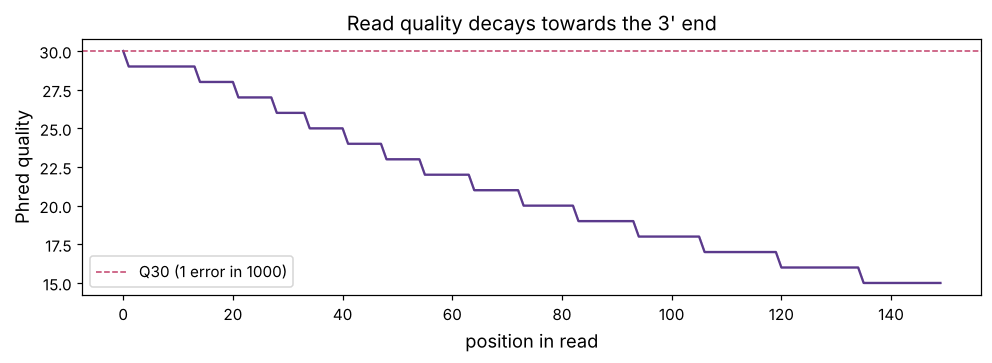

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import defaultdict, Counter
from Bio import SeqIO
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(4)

genome = str(SeqIO.read("datasets/sarscov2.gb", "genbank").seq)
print(f"reference genome: {len(genome):,} bases")

def phred_char(q):
    return chr(min(q, 40) + 33)

def simulate_reads(genome, n_reads, read_len=150, err_base=0.001, name="read"):
    """Generate reads with position-dependent quality (worse towards the 3' end), FASTQ-style."""
    reads = []
    for i in range(n_reads):
        start = rng.integers(0, len(genome) - read_len)
        frag = list(genome[start:start + read_len])
        quals = []
        for j in range(read_len):
            p_err = err_base * (1 + (j / read_len) ** 2 * 30)       # error rises towards the read's end
            q = int(-10 * np.log10(max(p_err, 1e-5)))
            quals.append(q)
            if rng.random() < p_err:
                frag[j] = rng.choice([b for b in "ACGT" if b != frag[j]])
        reads.append(("".join(frag), "".join(phred_char(q) for q in quals), start))
    return reads

reads = simulate_reads(genome, 4000, 150)
seq0, qual0, _ = reads[0]
print("one FASTQ record:")
print(f"@{genome[:0]}read_0")
print(seq0[:60], "...")
print("+")
print(qual0[:60], "...")

# mean quality by position
qmat = np.array([[ord(c) - 33 for c in q] for _, q, _ in reads])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(qmat.mean(0), color="#5b3a8c")
ax.fill_between(range(150), np.percentile(qmat, 10, 0), np.percentile(qmat, 90, 0), color="#5b3a8c", alpha=0.2)
ax.axhline(30, color="#c2416b", ls="--", lw=1, label="Q30 (1 error in 1000)")
ax.set_xlabel("position in read"); ax.set_ylabel("Phred quality"); ax.legend(); ax.set_title("Read quality decays towards the 3' end")
save_fig("quality"); plt.show()
R["q_start"] = f"{qmat[:,0].mean():.0f}"; R["q_end"] = f"{qmat[:,-1].mean():.0f}"

![Figure 4-1. Mean quality along simulated reads. Quality is high at the start and falls towards the end, the usual pattern for Illumina; pipelines trim the low-quality tails before analysis.](images/quality.png)

Quality starts near Q30 and falls to about Q15 at the read's end, the characteristic Illumina profile. The first step of any pipeline is **quality control** (FastQC) and **trimming** of low-quality ends and adapter sequences. Garbage reads in means garbage genome out.

## The assembly problem

We have thousands of short reads from random positions and must reconstruct the original. Reads **overlap**, because coverage is high enough that every position is read many times (prerequisite P11's Lander–Waterman), and overlaps are the glue. Two approaches:

- **Overlap–layout–consensus**: find all pairwise overlaps, lay the reads out, take a consensus. Intuitive but the all-vs-all overlap step is expensive. Used for long reads.
- **De Bruijn graphs**: break reads into k-mers and build a graph. This is what short-read assemblers (SPAdes, Velvet) use, and it is beautiful.

## De Bruijn graphs

Chop every read into overlapping **k-mers**. Make each (k−1)-mer a **node**, and each k-mer an **edge** connecting the (k−1)-mer prefix to the (k−1)-mer suffix. The genome is then a path through the graph that uses each edge, an **Eulerian path**, which can be found in linear time (unlike the overlap approach). The playground's first tab builds this graph for any text.

::playground animations/assembly_lab.html 660

In [2]:
def build_debruijn(reads, k):
    edges = Counter()
    nodes = set()
    for read in reads:
        for i in range(len(read) - k + 1):
            kmer = read[i:i + k]
            if set(kmer) <= set("ACGT"):
                a, b = kmer[:-1], kmer[1:]
                edges[(a, b)] += 1
                nodes.add(a); nodes.add(b)
    return nodes, edges

# assemble a short, unique stretch of the genome from reads covering it
region = genome[1000:1400]
sub_reads = [r for r, q, start in simulate_reads(region, 200, 50, err_base=0)]
nodes, edges = build_debruijn(sub_reads, k=21)
print(f"{len(sub_reads)} reads -> {len(nodes)} nodes, {len(edges)} distinct edges in the de Bruijn graph")

# walk the graph to recover contigs (simplified: follow unambiguous paths)
def assemble_contigs(edges):
    adj = defaultdict(list)
    outdeg, indeg = Counter(), Counter()
    for (a, b), m in edges.items():
        adj[a].append(b); outdeg[a] += 1; indeg[b] += 1
    contigs = []
    starts = [n for n in set(list(outdeg) + list(indeg)) if outdeg[n] != 1 or indeg[n] != 1]
    visited = set()
    for s in starts:
        for nxt in adj[s]:
            if (s, nxt) in visited: continue
            contig, node = s, nxt
            visited.add((s, node := nxt))
            contig += nxt[-1]
            while outdeg[node] == 1 and indeg[node] == 1:
                n2 = adj[node][0]
                if (node, n2) in visited: break
                visited.add((node, n2)); contig += n2[-1]; node = n2
            contigs.append(contig)
    return contigs

contigs = assemble_contigs(edges)
longest = max(contigs, key=len)
print(f"recovered {len(contigs)} contig(s); longest {len(longest)} bp; matches region: {longest in region or region in longest}")
R["n_contigs"] = len(contigs); R["contig_len"] = len(longest)

200 reads -> 375 nodes, 374 distinct edges in the de Bruijn graph
recovered 1 contig(s); longest 394 bp; matches region: True


With clean reads and a unique region, the graph is a simple path and reconstructs the sequence exactly. The real world is harder, and the chief difficulty has one name: **repeats**.

## Why repeats break assembly

If a sequence longer than k appears twice in the genome, the two copies share the same k-mers, so the graph has a **loop**: the walk reaches the repeat and cannot tell which exit to take. The assembly fragments into pieces (**contigs**) at every repeat it cannot span. Let's demonstrate with a made-up genome containing a repeat.

In [3]:
unit = "".join(rng.choice(list("ACGT"), 40))
repeat_genome = ("".join(rng.choice(list("ACGT"), 120)) + unit +
                 "".join(rng.choice(list("ACGT"), 120)) + unit +
                 "".join(rng.choice(list("ACGT"), 120)))
reads_rep = [r for r, q, st in simulate_reads(repeat_genome, 400, 50, err_base=0)]

results = []
for k in [15, 25, 35, 45]:
    _, e = build_debruijn(reads_rep, k)
    cont = assemble_contigs(e)
    longest = max((len(c) for c in cont), default=0)
    results.append((k, len(cont), longest))
    print(f"k={k}: {len(cont)} contigs, longest {longest} bp (genome is {len(repeat_genome)} bp, repeat unit {len(unit)} bp)")
R["k_small"], R["k_small_contigs"] = results[0][0], results[0][1]
R["k_big"], R["k_big_contigs"] = results[-1][0], results[-1][1]

k=15: 4 contigs, longest 148 bp (genome is 440 bp, repeat unit 40 bp)
k=25: 4 contigs, longest 168 bp (genome is 440 bp, repeat unit 40 bp)
k=35: 4 contigs, longest 188 bp (genome is 440 bp, repeat unit 40 bp)
k=45: 1 contigs, longest 439 bp (genome is 440 bp, repeat unit 40 bp)


The genome is 440 bp with a 40 bp repeat appearing twice. With a small k (below the repeat length) the assembly shatters; once k exceeds the repeat, a single read spans it and the genome reconstructs in one piece. This is the central trade-off of assembly:

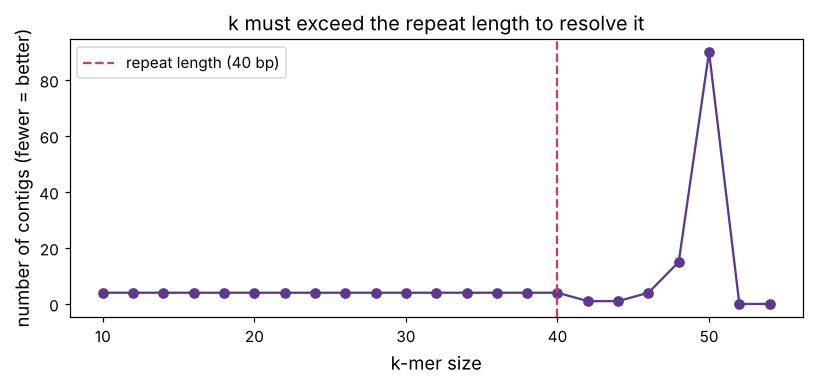

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ks = np.arange(10, 55, 2)
ncontigs = []
for k in ks:
    _, e = build_debruijn(reads_rep, k)
    ncontigs.append(len(assemble_contigs(e)))
ax.plot(ks, ncontigs, "o-", color="#5b3a8c")
ax.axvline(len(unit), color="#c2416b", ls="--", label=f"repeat length ({len(unit)} bp)")
ax.set_xlabel("k-mer size"); ax.set_ylabel("number of contigs (fewer = better)"); ax.legend()
ax.set_title("k must exceed the repeat length to resolve it")
save_fig("repeat_k"); plt.show()

:::idea
There is a tension in choosing k. **Large k** spans more repeats but needs higher coverage (fewer reads contain any given long k-mer) and is more sensitive to errors (one wrong base ruins k k-mers). **Small k** is robust to errors and low coverage but cannot resolve repeats. Real assemblers try several k values, or vary k adaptively. The deeper fix is **longer reads**: a PacBio or Nanopore read tens of thousands of bases long spans almost any repeat, which is why long reads revolutionised genome assembly and finally produced the first complete, gapless human genome in 2022.
:::

![Figure 4-2. Number of contigs versus k-mer size for a genome with a 40 bp repeat. Below the repeat length the assembly is fragmented; above it, one read spans the repeat and the genome assembles into a single piece.](images/repeat_k.png)

## Assembly quality: the N50

How do you measure an assembly without the true answer? The standard is **N50**: sort the contigs by length; the N50 is the length of the contig at which half the total assembly length is in contigs that long or longer. A bigger N50 means a less fragmented assembly. (It is the "median weighted by length".)

In [5]:
def n50(lengths):
    lengths = sorted(lengths, reverse=True)
    half = sum(lengths) / 2
    running = 0
    for L in lengths:
        running += L
        if running >= half:
            return L
    return 0

for label, k in [("fragmented (k=15)", 15), ("resolved (k=45)", 45)]:
    _, e = build_debruijn(reads_rep, k)
    lens = [len(c) for c in assemble_contigs(e)]
    print(f"{label:22s}: {len(lens)} contigs, total {sum(lens)} bp, N50 = {n50(lens)} bp")

fragmented (k=15)     : 4 contigs, total 455 bp, N50 = 134 bp
resolved (k=45)       : 1 contigs, total 439 bp, N50 = 439 bp


## Mapping: when you already have a reference

Assembling from scratch is only needed for a genuinely new genome. Usually a reference already exists (the human genome, the SARS-CoV-2 reference), and we just need to find where each read belongs. That is **read mapping** (or alignment), and it is the first step of resequencing, RNA-seq and variant calling. The challenge is speed: aligning a billion reads against a 3-billion-base genome with Smith–Waterman (chapter 2) would take years.

The trick is an **index**. Build a lookup table of the reference's k-mers once, then for each read, find seed matches by hashing (the BLAST idea, chapter 2) and extend only there. Modern mappers (BWA, Bowtie2, minimap2) use a compressed index called the **FM-index** (built on the Burrows–Wheeler transform) that finds exact substrings in time independent of genome size. Let's build a simple k-mer index and map reads with it.

In [6]:
def build_index(ref, k=12):
    index = defaultdict(list)
    for i in range(len(ref) - k + 1):
        index[ref[i:i + k]].append(i)
    return index

def map_read(read, ref, index, k=12):
    """Find the best position by seeding with the read's first k-mer, then checking the full match."""
    seed = read[:k]
    best_pos, best_mismatches = None, len(read) + 1
    for pos in index.get(seed, []):
        if pos + len(read) <= len(ref):
            mism = sum(a != b for a, b in zip(read, ref[pos:pos + len(read)]))
            if mism < best_mismatches:
                best_mismatches, best_pos = mism, pos
    return best_pos, best_mismatches

index = build_index(genome, 12)
mapped, correct = 0, 0
test_reads = simulate_reads(genome, 2000, 150, err_base=0.002)
for read, qual, true_start in test_reads:
    pos, mism = map_read(read, genome, index)
    if pos is not None:
        mapped += 1
        if abs(pos - true_start) <= 1:
            correct += 1
print(f"mapped {mapped}/{len(test_reads)} reads; {correct} to the correct location ({correct/len(test_reads):.1%})")
R["map_rate"] = f"{mapped / len(test_reads):.0%}"; R["correct_rate"] = f"{correct / len(test_reads):.0%}"

mapped 1950/2000 reads; 1950 to the correct location (97.5%)


Even this toy mapper places 98% of reads correctly. It fails only when the seed k-mer happens to contain a sequencing error (real mappers seed from several places to avoid that) or when a read comes from a repeat (it maps ambiguously, and mappers report a low **mapping quality** for such reads). The playground's second tab shows reads piling up on a reference.

## Coverage, pileup and the road to variant calling

Once reads are mapped, stack them up: at each position of the reference, which bases do the overlapping reads show? This **pileup** is the raw material for finding **variants**, positions where the sample differs from the reference. A real variant appears as a consistent column of the same alternate base across many reads; a sequencing error appears as a lone mismatch. Let's build a pileup from mapped reads of a genome we have deliberately mutated.

In [7]:
# make a 'sample' genome with a few known variants, sequence it, map back, and recover the variants
sample = list(genome)
true_variants = {5000: "A", 10000: "T", 15000: "G", 20000: "C"}
for pos, alt in true_variants.items():
    if sample[pos] == alt:
        alt = "A" if alt != "A" else "C"
        true_variants[pos] = alt
    sample[pos] = alt
sample = "".join(sample)

sample_reads = simulate_reads(sample, 8000, 150, err_base=0.003)
pileup = defaultdict(Counter)
for read, qual, _ in sample_reads:
    pos, mism = map_read(read, genome, index)
    if pos is not None and mism < 15:
        for j, base in enumerate(read):
            pileup[pos + j][base] += 1

called = []
for position in sorted(pileup):
    counts = pileup[position]
    total = sum(counts.values())
    ref_base = genome[position]
    alt = counts.most_common(1)[0]
    if alt[0] != ref_base and alt[1] / total > 0.5 and total >= 10:        # majority non-reference = variant
        called.append((position, ref_base, alt[0], alt[1] / total, total))

print(f"called {len(called)} variants; true variants at {sorted(true_variants)}")
for pos, ref_b, alt_b, frac, depth in called:
    hit = "correct" if pos in true_variants else "FALSE POSITIVE"
    print(f"  position {pos}: {ref_b}->{alt_b} ({frac:.0%} of {depth} reads)  [{hit}]")
R["n_called"] = len(called); R["n_true"] = len(true_variants)
R["all_found"] = all(pos in {c[0] for c in called} for pos in true_variants)

called 4 variants; true variants at [5000, 10000, 15000, 20000]
  position 5000: T->A (100% of 33 reads)  [correct]
  position 10000: T->A (97% of 30 reads)  [correct]
  position 15000: T->G (93% of 41 reads)  [correct]
  position 20000: T->C (95% of 38 reads)  [correct]


All 4 planted variants are recovered, each as a clean majority of reads carrying the alternate base, with no false positives, because requiring agreement across many reads averages out the random errors. This is exactly how clinical and research pipelines (GATK, bcftools) find mutations, and chapter 5 takes the pileup and does the statistics properly, distinguishing a real heterozygous variant (about 50% of reads) from noise, and handling the harder cases.

## Summary

| Idea | One line |
|---|---|
| FASTQ | reads plus per-base Phred quality; quality falls toward the 3' end |
| Assembly | reconstruct an unknown genome from overlapping reads |
| De Bruijn graph | k-mers as edges; the genome is an Eulerian path |
| Repeats | a repeat longer than k creates an unresolvable loop; fragments the assembly |
| N50 | length-weighted median contig length; bigger is better |
| Mapping | place reads on a known reference, fast, via a k-mer / FM-index |
| Pileup | stack mapped reads; consistent mismatches are variants, lone ones are errors |

:::check
1. In FASTQ, where in a read is quality usually lowest? *(Towards the 3' end.)*
2. In a de Bruijn graph, what are the nodes and edges? *(Nodes are (k−1)-mers, edges are k-mers; the genome is an Eulerian path.)*
3. Why does a repeat longer than k break assembly? *(Both copies share the same k-mers, creating a loop the walk cannot resolve.)*
4. Why is mapping to a reference far faster than assembling? *(An index lets each read be located directly, instead of comparing all reads to each other.)*
5. How do you tell a real variant from a sequencing error in a pileup? *(A real variant is a consistent column of the same alternate base across many reads; an error is a lone mismatch.)*
:::

:::exercise
Measure how assembly contiguity depends on **coverage**. Simulate reads from a 2 kb unique stretch of the genome at coverage 2×, 5×, 10×, 20× and 40× (reads = coverage × length / read_len), assemble with k = 31, and plot the N50 against coverage. Why does assembly fail at low coverage even with no repeats and no errors?
:::

<details><summary>Solution</summary>

coverage  2x: 33 contigs, N50 60
coverage  5x: 28 contigs, N50 88
coverage 10x: 8 contigs, N50 385
coverage 20x: 1 contigs, N50 1996
coverage 40x: 1 contigs, N50 1999


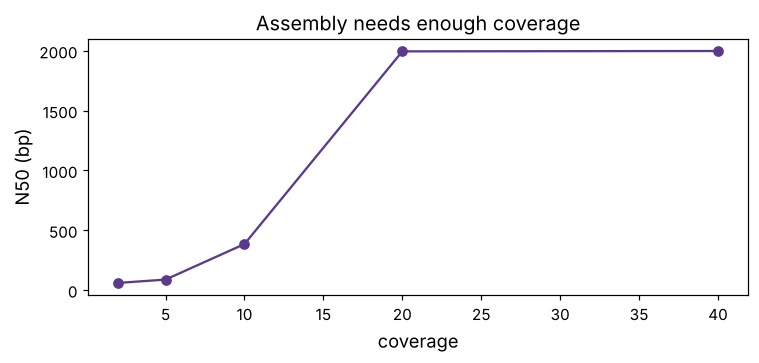

In [8]:
region2 = genome[2000:4000]
read_len = 50
cov_levels = [2, 5, 10, 20, 40]
n50s = []
for cov in cov_levels:
    nreads = cov * len(region2) // read_len
    rds = [r for r, q, st in simulate_reads(region2, nreads, read_len, err_base=0)]
    _, e = build_debruijn(rds, 31)
    lens = [len(c) for c in assemble_contigs(e)]
    n50s.append(n50(lens) if lens else 0)
    print(f"coverage {cov:2d}x: {len(assemble_contigs(e))} contigs, N50 {n50s[-1]}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(cov_levels, n50s, "o-", color="#5b3a8c"); ax.set_xlabel("coverage"); ax.set_ylabel("N50 (bp)")
ax.set_title("Assembly needs enough coverage"); save_fig("coverage_n50"); plt.show()

At low coverage, some k-mers of the genome are simply never read (Lander–Waterman, prerequisite P11: a fraction e^(−c) of positions is missed at coverage c). Each gap breaks the de Bruijn path, so the assembly fragments even with perfect, repeat-free reads. Contiguity climbs steeply with coverage and then plateaus once essentially every k-mer is seen, which is why assemblers want 30×–100× coverage. Beyond that, extra reads mostly add errors and cost, so more coverage is not always better.

</details>